# Energy loss and linear-wind analysis
Analyze `energy_loss_nH1.0.bin`, written by `energy_loss.cpp`. Each native-endian float64 record is `(x, y, z, E)`, with positions in pc and **total** proton energy in GeV.

The reference assumes injection a deterministic logarithmic injection grid, $dN/dE_0\propto E_0^{-1}$, constant hydrogen density, $u_z=az$, initial positions at the origin, and no escape boundaries. Parameters are fixed below, not fitted. The binary has no run metadata: confirm these settings match the producing run. Record order preserves the initial logarithmic energy grid. The notebook prefers the binary in the project directory, where the current C++ program writes it; the selected path is printed below.

In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import PchipInterpolator

# Run from output/ or the project directory. Prefer the current C++ output.
project_dir = Path.cwd()
if project_dir.name == 'output':
    project_dir = project_dir.parent
file = project_dir / 'energy_loss_nH1.0.bin'
if not file.exists():
    file = project_dir / 'output' / 'energy_loss_nH1.0.bin' 
E_min, E_max = 10.0, 1e6  # initial total energy, GeV
m_p = 0.938272           # rest energy, GeV
nH = 1.0                # cm^-3
a = 1e-8                # div(u), yr^-1; u_z = a*z
t_end = 1e8             # yr
include_hadronic_loss = True
expected_particles = 10000
c_cm_s = 2.99792458e10
c_pc_yr = 0.30660139
yr2s = 31557600.0

In [7]:
if not file.exists():
    raise FileNotFoundError(f"Cannot find {file.resolve()}; set file to the binary path.")
if file.stat().st_size == 0 or file.stat().st_size % 32:
    raise ValueError("Expected nonempty records of four float64 values (32 bytes each).")
data = np.fromfile(file, dtype="=f8").reshape(-1, 4)
if not np.isfinite(data).all() or np.any(data[:, 3] <= m_p):
    raise ValueError("Nonfinite data or total energy at/below proton rest energy.")
xyz, E = data[:, :3], data[:, 3]
x, y, z = xyz.T
T = E - m_p
N = len(E)
print(f"Particles: {N} (expected {expected_particles})")
print("Total energy min / median / max [GeV]:", np.percentile(E, [0, 50, 100]))
print("Kinetic energy min / median / max [GeV]:", np.percentile(T, [0, 50, 100]))
print("Mean position [pc]:", xyz.mean(axis=0))
print("Coordinate standard deviations [pc]:", xyz.std(axis=0, ddof=1))
if N != expected_particles:
    raise ValueError("Particle count differs from the configured injection grid")
E0 = np.geomspace(E_min, E_max, N)
print("Selected binary:", file.resolve())

Particles: 10000 (expected 10000)
Total energy min / median / max [GeV]: [2.50875120e+00 4.28786332e+02 6.32556212e+04]
Kinetic energy min / median / max [GeV]: [1.57047920e+00 4.27848060e+02 6.32546829e+04]
Mean position [pc]: [ 454.41975704  -78.56928574 -270.65147718]
Coordinate standard deviations [pc]: [18412.27875568 18057.78583552 34415.93182615]
Selected binary: /Users/lichaomi/Downloads/research/CR_advection/Monte_Carlo/energy_loss_nH1.0.bin


## Continuous-loss and spatial reference
For $T=E-m_p$,
$$\dot E=-\frac{a}{3}\frac{E^2-m_p^2}{E}-\frac12 n_H\sigma_{pp}(T)cT.$$
The code below includes the seconds-to-years conversion. With only adiabatic loss,
$$E(t)=\sqrt{m_p^2+(E_0^2-m_p^2)e^{-2at/3}}.$$

For the simulation's random steps, $D(E)=c_{\rm pc/yr}\lambda(E)/3$ with $\lambda=2(\mathcal R/10\,\mathrm{GV})^{1/3}$ pc, where $\mathcal R[\mathrm{GV}]=\sqrt{E^2-m_p^2}$ for protons with $E$ in GeV. Conditional on initial energy, the diffusion-limit variances satisfy
$$\dot V_x=\dot V_y=2D(E(t)),\qquad \dot V_z=2aV_z+2D(E(t)).$$
We integrate the cooling and variance equations together. This accounts for changing diffusion during cooling and vertical stretching by the wind; the constant-$D$ formula is not assumed.

Combined-loss predicted final range [GeV]: [2.50875123e+00 6.32558015e+04]
Adiabatic-only predicted final range [GeV]: [7.19514262e+00 7.16531311e+05]
Adiabatic momentum ratio: 0.7165313105737893


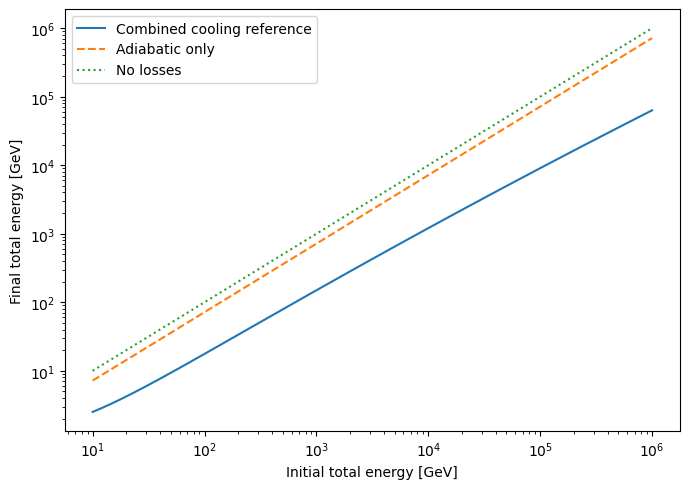

In [8]:
def sigma_pp(T):
    T = np.asarray(T, dtype=float)
    threshold = 0.2797
    safe = np.maximum(T, threshold)
    log_ratio = np.log(safe / threshold)
    sigma = (30.7 - 0.96*log_ratio + 0.18*log_ratio**2)
    sigma *= (1 - (threshold/safe)**1.9)**3 * 1e-27
    return np.where(T > threshold, sigma, 0.0)


def diffusion(E):
    total = np.asarray(E)
    rigidity = np.sqrt((total - m_p) * (total + m_p))  # GV, proton Z=1
    mean_free_path = 2.0 * (rigidity / 10.0)**(1/3)     # pc
    return c_pc_yr * mean_free_path / 3.0             # pc^2/yr


E0_grid = np.geomspace(E_min, E_max, 1025)
M = len(E0_grid)


def reference_rhs(q, state):
    # q = t/t_end. Integrate log(T) to maintain positive kinetic energy.
    logT, Vxy, Vz = state.reshape(3, M)
    kinetic = np.exp(logT)
    total = kinetic + m_p
    dlogT_dt = -(a/3) * (total + m_p) / total
    if include_hadronic_loss:
        dlogT_dt -= 0.5 * nH * sigma_pp(kinetic) * c_cm_s * yr2s
    D = diffusion(total)
    return (t_end * np.array([dlogT_dt, 2*D, 2*a*Vz + 2*D])).ravel()


state0 = np.concatenate([np.log(E0_grid-m_p), np.zeros(2*M)])
sol = solve_ivp(reference_rhs, (0, 1), state0, rtol=1e-9, atol=1e-10)
if not sol.success:
    raise RuntimeError(sol.message)
logTf, Vxy_grid, Vz_grid = sol.y[:, -1].reshape(3, M)
Ef_grid = m_p + np.exp(logTf)
assert np.all(np.diff(Ef_grid) > 0)
Ead_grid = np.sqrt(m_p**2 + (E0_grid**2-m_p**2)*np.exp(-2*a*t_end/3))
print("Combined-loss predicted final range [GeV]:", Ef_grid[[0, -1]])
print("Adiabatic-only predicted final range [GeV]:", Ead_grid[[0, -1]])
print("Adiabatic momentum ratio:", np.exp(-a*t_end/3))

plt.figure(figsize=(7, 5))
plt.loglog(E0_grid, Ef_grid, label="Combined cooling reference")
plt.loglog(E0_grid, Ead_grid, "--", label="Adiabatic only")
plt.loglog(E0_grid, E0_grid, ":", label="No losses")
plt.xlabel("Initial total energy [GeV]")
plt.ylabel("Final total energy [GeV]")
plt.legend()
plt.tight_layout()
plt.show()

## Energy spectrum, cumulative distribution, and cooling residuals
The injection is a deterministic logarithmic grid: $dN/dE_0\propto E_0^{-1}$, so its continuum CDF is logarithmic. Predicted counts are integrated over each bin using the inverse cooling map. The actual discrete injection histogram is shown as well.

The left panel uses counts/$\Delta E$; the right uses counts/$\Delta\ln E$, the bin average of $E\,dN/dE$. There is no volume or flux normalization. Poisson error bars and standard KS p-values are omitted because the energies are a deterministic grid evolved under spatially uniform loss coefficients, not independent random samples. Compare record-by-record cooling residuals instead.

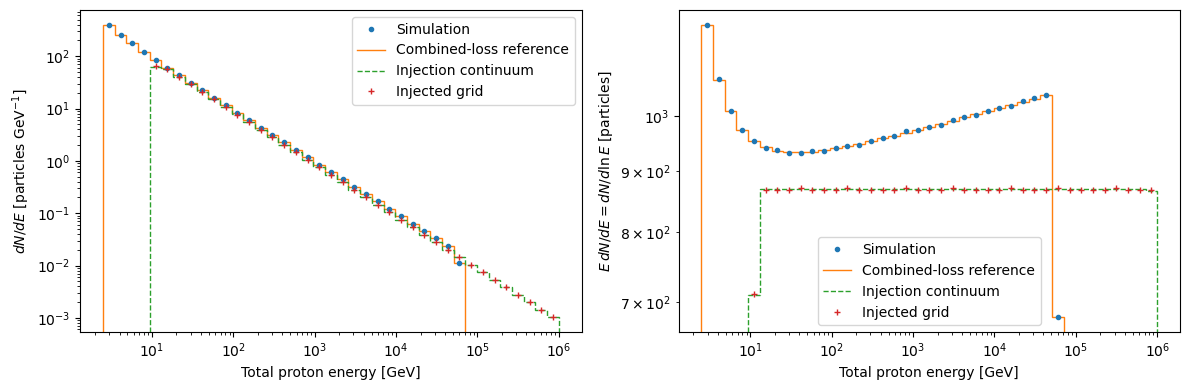

CDF distance (no KS p-value): 0.0001
Particles outside continuous-reference support: 1
Max absolute relative cooling residual: 2.8505004049796222e-06
RMS relative cooling residual: 8.917203623460834e-07


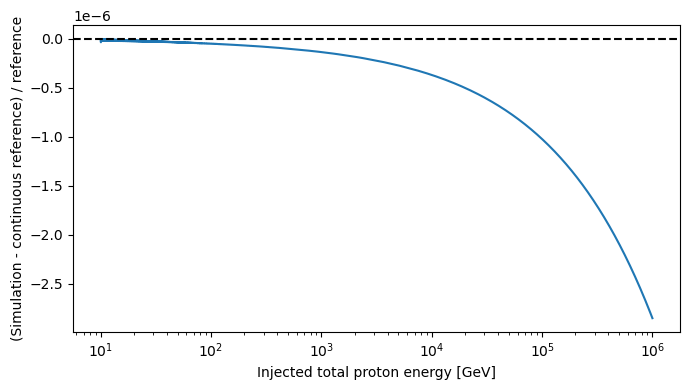

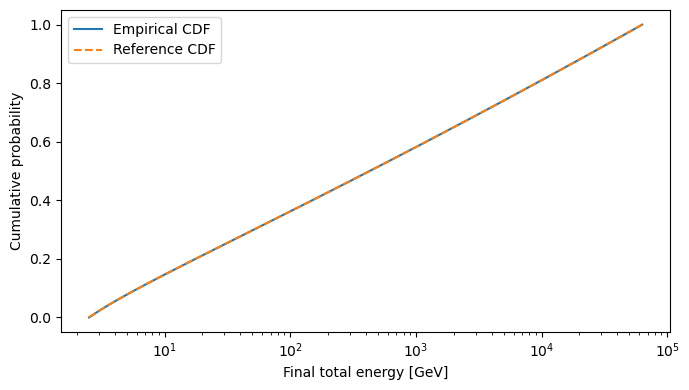

In [9]:
inverse_cooling = PchipInterpolator(np.log(Ef_grid), np.log(E0_grid), extrapolate=False)


def initial_cdf(energy):
    energy = np.clip(np.asarray(energy, dtype=float), E_min, E_max)
    return np.log(energy / E_min) / np.log(E_max / E_min)


def final_cdf(energy):
    energy = np.asarray(energy, dtype=float)
    clipped = np.clip(energy, Ef_grid[0], Ef_grid[-1])
    initial = np.exp(inverse_cooling(np.log(clipped)))
    return np.clip(initial_cdf(initial), 0, 1)


bins = np.geomspace(min(E.min(), Ef_grid[0], E_min)*0.999,
                    max(E.max(), E_max)*1.001, 40)
counts, _ = np.histogram(E, bins)
predicted = N * np.diff(final_cdf(bins))
injected = N * np.diff(initial_cdf(bins))
injected_discrete, _ = np.histogram(E0, bins)
width = np.diff(bins)
centers = np.sqrt(bins[:-1]*bins[1:])
good = counts > 0
assert counts.sum() == N and np.isclose(predicted.sum(), N)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dlnE = np.diff(np.log(bins))
for ax, factor, ylabel in zip(axes, [1/width, 1/dlnE],
                            [r"$dN/dE$ [particles GeV$^{-1}$]",
                             r"$E\,dN/dE = dN/d\ln E$ [particles]"]):
    ax.plot(centers[good], (counts*factor)[good], "o", ms=3, label="Simulation")
    ax.stairs(predicted*factor, bins, label="Combined-loss reference")
    ax.stairs(injected*factor, bins, linestyle="--", label="Injection continuum")
    occupied = injected_discrete > 0
    ax.plot(centers[occupied], (injected_discrete*factor)[occupied],
            "+", ms=4, label="Injected grid")
    ax.set(xscale="log", yscale="log", xlabel="Total proton energy [GeV]", ylabel=ylabel)
    ax.legend()
fig.tight_layout()
plt.show()

# CDF distance is descriptive; no iid-sample KS significance is assigned.
ordered = np.sort(E)
reference_cdf = final_cdf(ordered)
cdf_distance = max(np.max(np.arange(1, N+1)/N - reference_cdf),
                   np.max(reference_cdf - np.arange(N)/N))
print(f"CDF distance (no KS p-value): {cdf_distance:.6g}")
print("Particles outside continuous-reference support:",
      np.count_nonzero((E < Ef_grid[0]) | (E > Ef_grid[-1])) )

cooling_map = PchipInterpolator(np.log(E0_grid), np.log(Ef_grid))
E_reference = np.exp(cooling_map(np.log(E0)))
relative_residual = (E - E_reference) / E_reference
print("Max absolute relative cooling residual:", np.max(np.abs(relative_residual)))
print("RMS relative cooling residual:", np.sqrt(np.mean(relative_residual**2)))
plt.figure(figsize=(7, 4))
plt.semilogx(E0, relative_residual)
plt.axhline(0, color="black", ls="--")
plt.xlabel("Injected total proton energy [GeV]")
plt.ylabel("(Simulation - continuous reference) / reference")
plt.tight_layout()
plt.show()

ordered = np.sort(E)
plt.figure(figsize=(7, 4))
plt.semilogx(ordered, np.arange(1, N+1)/N, label="Empirical CDF")
plt.semilogx(Ef_grid, initial_cdf(E0_grid), "--", label="Reference CDF")
plt.xlabel("Final total energy [GeV]")
plt.ylabel("Cumulative probability")
plt.legend()
plt.tight_layout()
plt.show()

## Spatial projections and energy-dependent spreading
The expected center remains the origin for this symmetric wind and injection. Variance predictions below average the cooling-history reference over the observed energies in each bin. Sparse bins are omitted. Vertical variance is amplified by the wind and should not be interpreted as an isotropic diffusion coefficient.

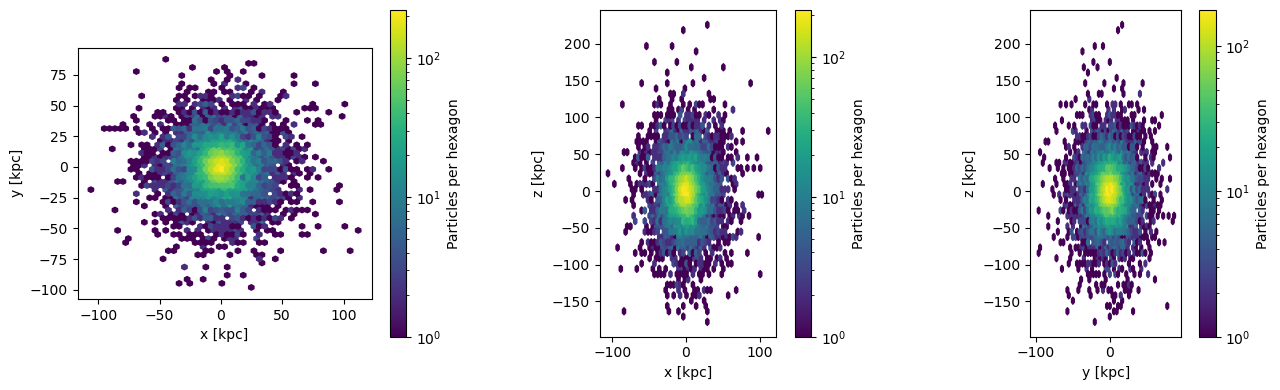

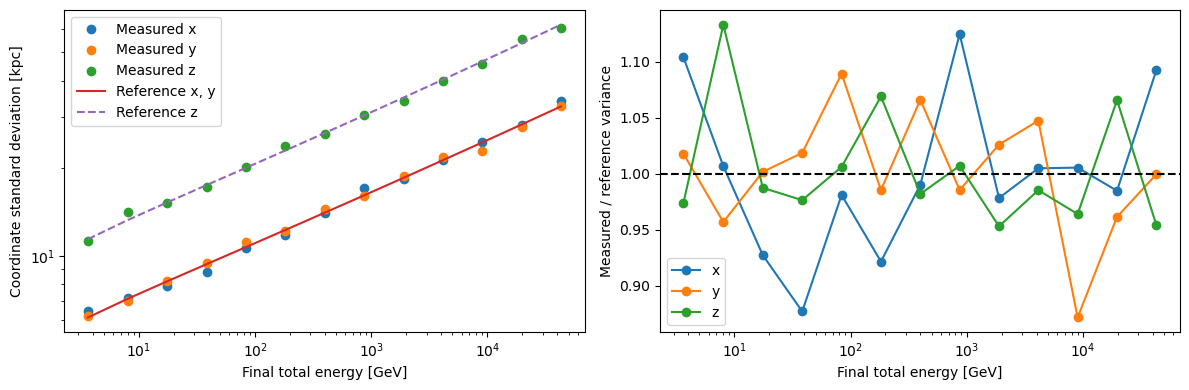

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    image = ax.hexbin(xyz[:, i]/1000, xyz[:, j]/1000, gridsize=50, mincnt=1, bins="log")
    ax.set(xlabel=f"{'xyz'[i]} [kpc]", ylabel=f"{'xyz'[j]} [kpc]", aspect="equal")
    fig.colorbar(image, ax=ax, label="Particles per hexagon")
fig.tight_layout()
plt.show()

variance_xy = PchipInterpolator(np.log(Ef_grid), Vxy_grid, extrapolate=False)
variance_z = PchipInterpolator(np.log(Ef_grid), Vz_grid, extrapolate=False)
spatial_bins = np.geomspace(E.min()*0.999, E.max()*1.001, 14)
rows = []
for low, high in zip(spatial_bins[:-1], spatial_bins[1:]):
    selected = (E >= low) & (E < high)
    count = selected.sum()
    if count < 30:
        continue
    measured = xyz[selected].var(axis=0, ddof=1)
    log_energy = np.log(np.clip(E[selected], Ef_grid[0], Ef_grid[-1]))
    theory = np.array([variance_xy(log_energy).mean(), variance_z(log_energy).mean()])
    rows.append([np.exp(np.log(E[selected]).mean()), count, *measured, *theory])
if not rows:
    raise ValueError("No spatial bins have 30 particles; reduce bin count.")
summary = np.asarray(rows)
energy_bin, number_bin, vx, vy, vz, vxy_ref, vz_ref = summary.T
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for values, label in [(vx, "x"), (vy, "y"), (vz, "z")]:
    axes[0].loglog(energy_bin, np.sqrt(values)/1000, "o", label=f"Measured {label}")
axes[0].loglog(energy_bin, np.sqrt(vxy_ref)/1000, "-", label="Reference x, y")
axes[0].loglog(energy_bin, np.sqrt(vz_ref)/1000, "--", label="Reference z")
axes[0].set(xlabel="Final total energy [GeV]", ylabel="Coordinate standard deviation [kpc]")
axes[0].legend()
for measured, reference, label in [(vx, vxy_ref, "x"), (vy, vxy_ref, "y"), (vz, vz_ref, "z")]:
    axes[1].semilogx(energy_bin, measured/reference, "o-", label=label)
axes[1].axhline(1, color="black", linestyle="--")
axes[1].set(xlabel="Final total energy [GeV]", ylabel="Measured / reference variance")
axes[1].legend()
fig.tight_layout()
plt.show()

## Interpretation and limits
The cooling reference solves the continuous combined-loss equation, whereas the simulation uses a frozen local wind, an exact adiabatic substep, and an explicit hadronic substep. Differences can include timestep and splitting error; quantify those with a refinement run. The spatial comparison uses the diffusion limit of the fixed-length random walk. Finite particle counts, especially in high-energy bins, cause scatter.

The injected energy grid is deterministic and recoverable from record order. The CDF distance is descriptive; an iid-sample KS p-value is not applicable. Energy residuals also include interpolation error from the reference grid. A small energy mismatch may place an endpoint just outside the continuous-reference support; inspect its magnitude rather than treating any such count as a failure. For future spatially varying divergence or gas density, cooling becomes trajectory dependent and the deterministic energy-map reference must be replaced. The spatial equations here also specifically assume the linear vertical wind.